# The LCR and the NSFR on the call reports of the bank that failed in 2023

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- compute the stock of high-quality liquid assets (HQLA) with the caps on Level 2 assets, the outflows and inflows by category, the cap on inflows and the liquidity coverage ratio (LCR), with every intermediate;
- say why the LCR of this case is "a Basel formula on call-report aggregates" and never the bank's reported or regulatory ratio;
- read how a mapping assumption about the customers moves the ratio from 20% to 72%;
- see what the net stable funding ratio (NSFR) needs that the call-report aggregates do not carry, and read the LCR against the survival period of the same bank.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed documents of case C16 (real FDIC call-report aggregates of the bank that failed on 2023-03-10 up to 2022-12-31, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `data/derived/C16/lcr-standard.json`: the variant that applies the Basel LCR to the balance sheet over 30 calendar days: the HQLA stock, the outflow and inflow rows, the net outflows, the ratio and the sensitivity to the customer mapping, plus the balance sheet.
- `data/derived/C16/list-adverse.json`: the LiST Adverse ladder of notebook 01, read here for the comparison with the survival period.

The rate tables are the Basel Framework's LCR standard (BCBS, LCR20 to LCR99, in force 2019-12-15) and NSFR standard (NSF20 to NSF99), held by the engine as module data with their paragraph; the engine never reproduces the text. The call report carries no customer type, so how a deposit is mapped to an LCR category is a convention of the product, proposed and stated, never a regulatory classification.

In [2]:
# Load the committed LCR document and the LiST Adverse document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
standard = json.loads((ROOT / "data" / "derived" / "C16" / "lcr-standard.json").read_text(encoding="utf-8"))
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
out = standard["outputs"]
lcr = out["lcr"]

for name, doc in (("lcr-standard", standard), ("list-adverse", adverse)):
    print(name, "| baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("label:", lcr["label"], "| reported or regulatory ratio:", lcr["reported_or_regulatory"])
print(lcr["statement"]["en"])

lcr-standard | baked by riskvalidation 0.8.1 | installed 0.8.1
list-adverse | baked by riskvalidation 0.8.1 | installed 0.8.1
label: basel-formula-on-call-report-aggregates | reported or regulatory ratio: False
A Basel LCR formula applied to FDIC call-report aggregates with stated assumptions and synthetic deposit behaviour: not the bank's reported or regulatory LCR.


## Method

### Step 1: the stock of HQLA and the caps

The stock is the sum of the Level 1, Level 2A and Level 2B assets after haircuts, less two adjustments that enforce the caps (Level 2 at most 40% of the stock, Level 2B at most 15%; Basel Framework LCR30.38 and LCR30.39, BCBS):

$$\mathrm{HQLA} = L_1 + L_{2A} + L_{2B} - \mathrm{Adj}_{15} - \mathrm{Adj}_{40}$$

$$\mathrm{Adj}_{15} = \max\!\Bigl(L_{2B} - \tfrac{15}{85}(L_1 + L_{2A}),\; L_{2B} - \tfrac{15}{60}L_1,\; 0\Bigr), \qquad \mathrm{Adj}_{40} = \max\!\Bigl(L_{2A} + L_{2B} - \mathrm{Adj}_{15} - \tfrac{2}{3}L_1,\; 0\Bigr)$$

Level 1 is unlimited. The next cell takes the three levels of the document, computes the two adjustments by hand from the equations (every intermediate) and then calls `hqla_stock`.

In [3]:
# The HQLA adjustments by hand from the equations, then the engine's stock, against the committed block
from riskvalidation.regulatory.lcr_nsfr import hqla_stock

levels = lcr["hqla"]
l1, l2a, l2b = levels["l1"], levels["l2a"], levels["l2b"]
adj15 = max(l2b - 15 / 85 * (l1 + l2a), l2b - 15 / 60 * l1, 0.0)
adj40 = max(l2a + l2b - adj15 - 2 / 3 * l1, 0.0)
by_hand = l1 + l2a + l2b - adj15 - adj40
stock = hqla_stock(l1, l2a, l2b)

print("L1, L2A, L2B (USD billions:)", round(l1 / 1e6, 3), round(l2a / 1e6, 3), round(l2b / 1e6, 3))
print("Adj15 =", round(adj15 / 1e6, 3), "| Adj40 =", round(adj40 / 1e6, 3), "| HQLA by hand =", round(by_hand / 1e6, 3))
print("engine: HQLA, Level 2 share, Level 2B share:", round(stock.hqla / 1e6, 3), round(stock.l2_share, 4), round(stock.l2b_share, 4))
print("same as the document:", bool(np.isclose(stock.hqla, levels["hqla"]) and np.isclose(stock.adj_40, levels["adj_40"])), "| caps:", levels["caps"])

L1, L2A, L2B (USD billions:) 18.909 31.204 0.0
Adj15 = 0.0 | Adj40 = 18.598 | HQLA by hand = 31.516
engine: HQLA, Level 2 share, Level 2B share: 31.516 0.4 0.0
same as the document: True | caps: {'l2_cap': 0.4, 'l2b_cap': 0.15}


The Level 2 cap binds exactly: the Level 2 share of the stock is 0.40. The bank holds more Level 2A assets than the cap lets count against its Level 1 assets (Level 2 may be at most two thirds of Level 1), so a part of them does not enter the stock.

### Step 2: outflows and inflows by category

Each category of the LCR has a rate: the outflow of a balance is $\text{balance} \times \text{rate}$, and the total is the sum over categories (LCR40 and LCR99). The engine holds the rates as `LCR_OUTFLOW_RATES` and `LCR_INFLOW_RATES`; `lcr_outflows` and `lcr_inflows` take the balances by category, refuse a category outside the table (a `KeyError` naming it) and return one row per category. The mapping of the call-report deposits to the categories is the document's (insured deposits as retail less stable, uninsured as non-financial corporates, foreign offices as other legal entities, a stated central mapping). The next cell calls both functions with the balances of the document.

In [4]:
# The outflow and inflow rows from the balances of the document
from riskvalidation.regulatory.lcr_nsfr import lcr_inflows, lcr_outflows

outflows = lcr_outflows({row["category"]: row["balance"] for row in lcr["outflows"]})
inflows = lcr_inflows({row["category"]: row["balance"] for row in lcr["inflows"]})

print(f"{'category':38s}{'balance (USD bn)':>26s}{'rate':>8s}{'amount (USD bn)':>26s}")
for side, result in (("outflows", outflows), ("inflows", inflows)):
    for row in result.rows:
        print(f"{row.key:38s}{row.balance / 1e6:26.3f}{row.rate:8.2f}{row.amount / 1e6:26.3f}   {side}")
    print(f"{'total':38s}{'':26s}{'':8s}{result.total / 1e6:26.3f}   {side}")
print("same totals as the document:", bool(np.isclose(outflows.total, lcr["total_outflows"]) and np.isclose(inflows.total, lcr["total_inflows"])))

category                                        balance (USD bn)    rate           amount (USD bn)
retail_less_stable                                         9.990    0.10                     0.999   outflows
non_financial_corporate                                  151.592    0.40                    60.637   outflows
other_legal_entity                                        13.899    1.00                    13.899   outflows
secured_other                                              1.757    1.00                     1.757   outflows
total                                                                                       77.292   outflows
secured_lending_other                                      0.707    1.00                     0.707   inflows
retail_and_nonfinancial_wholesale                         19.810    0.50                     9.905   inflows
total                                                                                       10.612   inflows
same totals as the docum

### Step 3: net outflows and the ratio

Inflows cannot offset more than 75% of the outflows, so the net outflow is never below a quarter of the outflows (LCR40.1), and the ratio is the stock over the net outflow (LCR20.4; at least 1 is required in normal times, and a ratio below 1 under stress is not a breach):

$$\mathrm{net} = O - \min(I,\; 0.75\,O), \qquad \mathrm{LCR} = \frac{\mathrm{HQLA}}{\mathrm{net}}$$

`net_cash_outflows` returns the inflows counted, the net outflow and whether the cap binds; `lcr_ratio` refuses a net outflow at or below zero (the ratio is undefined, never infinite). The next cell runs both.

In [5]:
# The net outflows with the 75 percent cap, and the ratio, against the committed values
from riskvalidation.regulatory.lcr_nsfr import lcr_ratio, net_cash_outflows

net = net_cash_outflows(outflows.total, inflows.total)
ratio = lcr_ratio(stock.hqla, net.net)

print("inflows counted (USD billions):", round(net.inflows_counted / 1e6, 3), "| cap binds:", net.cap_binds)
print("net outflows (USD billions):", round(net.net / 1e6, 3), "| committed:", round(lcr["net_outflows"] / 1e6, 3))
print("LCR =", round(ratio, 6), "| committed:", round(lcr["ratio"], 6), "| equal:", bool(np.isclose(ratio, lcr["ratio"])))
print("a ratio under 1 in stress is not a breach: the institution is expected to monitor its decline (the note of the document)")

inflows counted (USD billions): 10.612 | cap binds: False
net outflows (USD billions): 66.68 | committed: 66.68
LCR = 0.472641 | committed: 0.472641 | equal: True
a ratio under 1 in stress is not a breach: the institution is expected to monitor its decline (the note of the document)


### Step 4: the sensitivity to the customer mapping

The uninsured balance is 151.6 billion USD of 175.5 billion of deposits, so how it is classified decides the ratio. The document runs three mappings of that balance: as non-financial corporates (the central one, 40% outflow), as operational deposits (25%) and as other legal entities such as financial institutions (100%). The next cell reruns the engine with each category and compares with the committed band.

In [6]:
# Rerun the ratio with the uninsured balance in each of the three categories of the mapping band
uninsured = next(row["balance"] for row in lcr["outflows"] if row["category"] == "non_financial_corporate")
fixed = {row["category"]: row["balance"] for row in lcr["outflows"] if row["category"] != "non_financial_corporate"}
names = {"central": "central", "band-operational": "operational", "band-other-legal-entity": "other legal entities"}

print(f"{'mapping':28s}{'outflows (USD bn)':>30s}{'net (USD bn)':>26s}{'LCR':>10s}{'committed':>14s}")
band = []
for entry in lcr["mapping_sensitivity"]:
    balances = dict(fixed)
    balances[entry["lcr_category"]] = balances.get(entry["lcr_category"], 0.0) + uninsured
    total = lcr_outflows(balances).total
    netted = net_cash_outflows(total, inflows.total)
    value = lcr_ratio(stock.hqla, netted.net)
    band.append(value)
    print(f"{names[entry['mapping_id']]:28s}{total / 1e6:30.3f}{netted.net / 1e6:26.3f}{value:10.4f}{entry['ratio']:14.4f}")
print("same band as the document:", bool(np.allclose(band, [entry["ratio"] for entry in lcr["mapping_sensitivity"]])))

mapping                                  outflows (USD bn)              net (USD bn)       LCR     committed
central                                             77.292                    66.680    0.4726        0.4726
operational                                         54.553                    43.941    0.7172        0.7172
other legal entities                               168.247                   157.635    0.1999        0.1999
same band as the document: True


### Step 5: what the NSFR needs

The net stable funding ratio compares the stable funding a bank has with the stable funding its assets require (Basel Framework NSF20.2, BCBS):

$$\mathrm{NSFR} = \frac{\mathrm{ASF}}{\mathrm{RSF}} = \frac{\sum_i f_i^{\mathrm{ASF}}\, L_i}{\sum_j f_j^{\mathrm{RSF}}\, A_j}$$

where the factors $f$ depend on the **residual maturity** of each liability and asset (under 6 months, 6 months to 1 year, 1 year or more). The call report gives the balances but not those maturities for the securities and the loans, and the document commits no NSFR. This step is a teaching exercise, not a product result: it maps each balance to a factor of the engine's tables with a stated lower and upper bound where the maturity is unknown, and shows what the aggregates alone can say. The mapping below is this notebook's own assumption, labelled as such.

In [7]:
# A teaching mapping of the balance sheet to the NSFR factors, with a lower and an upper factor where the maturity is unknown
from riskvalidation.regulatory.lcr_nsfr import nsfr_asf, nsfr_ratio, nsfr_rsf

items = {item["item_id"]: item["amount"] for item in out["balance_sheet"]["items"]}
securities = items["securities-htm"] + items["securities-afs"]
# item: (amount, lower factor key, upper factor key); a single key twice means the maturity is not needed
liabilities = {
    "deposits-insured": (items["deposits-insured"], "less_stable_retail_deposits", "less_stable_retail_deposits"),
    "deposits-uninsured": (items["deposits-uninsured"], "funding_lt_1y_non_financial_corporates", "funding_lt_1y_non_financial_corporates"),
    "deposits-foreign": (items["deposits-foreign"], "other_liabilities", "other_funding_6m_to_1y"),
    "repo-borrowings": (items["repo-borrowings"], "other_liabilities", "other_liabilities"),
    "fhlb": (items["fhlb"], "other_liabilities", "long_term_liabilities_ge_1y"),
    "other-liabilities": (items["other-liabilities"], "other_liabilities", "other_liabilities"),
    "equity": (items["equity"], "regulatory_capital", "regulatory_capital"),
}
assets = {
    "cash": (items["cash"], "coins_banknotes_reserves", "coins_banknotes_reserves"),
    "reverse-repo": (items["reverse-repo"], "loans_fi_lt_6m_other", "loans_fi_lt_6m_other"),
    "securities": (securities, "unencumbered_level_1", "non_hqla_securities_ge_1y"),
    "loans": (items["loans"], "other_assets_lt_1y", "other_loans_ge_1y_rw_gt_35"),
    "other-assets": (items["other-assets"], "other_assets", "other_assets"),
}
# The engine's ASF and RSF under the lower and the upper factor of each item (items sharing a factor are summed first)
totals = {}
for name, table, engine in (("ASF", liabilities, nsfr_asf), ("RSF", assets, nsfr_rsf)):
    for position, bound in ((1, "lower"), (2, "upper")):
        grouped = {}
        for values in table.values():
            grouped[values[position]] = grouped.get(values[position], 0.0) + values[0]
        totals[(name, bound)] = engine(grouped)

print("balances in USD billions (liabilities, assets):", round(sum(v[0] for v in liabilities.values()) / 1e6, 3), round(sum(v[0] for v in assets.values()) / 1e6, 3))
print("ASF (lower, upper; USD billions):", round(totals[("ASF", "lower")] / 1e6, 3), round(totals[("ASF", "upper")] / 1e6, 3))
print("RSF (lower, upper; USD billions):", round(totals[("RSF", "lower")] / 1e6, 3), round(totals[("RSF", "upper")] / 1e6, 3))
print("NSFR band:", round(nsfr_ratio(totals[("ASF", "lower")], totals[("RSF", "upper")]), 4), "to", round(nsfr_ratio(totals[("ASF", "upper")], totals[("RSF", "lower")]), 4))

balances in USD billions (liabilities, assets): 209.026 209.026
ASF (lower, upper; USD billions): 100.243 122.192
RSF (lower, upper; USD billions): 47.67 167.277
NSFR band: 0.5993 to 2.5633


A band this wide says one thing: the aggregates alone do not identify the NSFR. The ratio could be below 1 or far above it depending on the maturities of 117 billion of securities and 74 billion of loans, which is the reason a product that rests on call-report aggregates commits the LCR (whose rates depend on customer types and the 30-day horizon) and no NSFR.

### Step 6: the LCR against the survival period

The same bank looks weak under the LCR and survives about two months under LiST Adverse. The two measures differ in what they assume about the **speed** of the outflows and about what counts as **liquid**. The next cell puts them side by side: the share of the deposit base that leaves in 30 days under each, and the HQLA stock against the CBC. The Basel report on the 2023 turmoil lists the LCR deposit outflow rates as 3% to 40% over 30 days (BCBS, 2023, Table A.1).

In [8]:
# The 30-day outflow share of deposits under the LCR and under LiST Adverse, and the HQLA stock against the CBC
from riskvalidation.liquidity.runoff import TABLE_A1_LCR_RANGE

lad = adverse["outputs"]["path"]["ladder"]
deposit_base = adverse["outputs"]["scoring"]["model_deposit_base"]
deposit_outflows = sum(sum(s["outflows"][:30]) for s in lad["segments"])
deposit_rows = ("retail_less_stable", "non_financial_corporate", "other_legal_entity")
lcr_deposit_outflows = sum(row["amount"] for row in lcr["outflows"] if row["category"] in deposit_rows)
low, high, days = TABLE_A1_LCR_RANGE
cumulative = np.cumsum(np.sum([s["outflows"] for s in lad["segments"]], axis=0)) / deposit_base
reach_day = int(np.argmax(cumulative >= lcr_deposit_outflows / deposit_base)) + 1

print("30-day outflow share of the deposit base, LCR:", round(lcr_deposit_outflows / deposit_base, 4))
print("30-day outflow share of the deposit base, LiST Adverse:", round(deposit_outflows / deposit_base, 4))
print("day on which LiST Adverse reaches the LCR share, and its share at day 125:", reach_day, round(float(cumulative[-1]), 4))
print("range of the LCR deposit rates in Table A.1 (low, high, days):", low, high, days)
print("HQLA stock and CBC (USD billions):", round(stock.hqla / 1e6, 3), round(adverse["outputs"]["cbc"]["total_liquidity_value"] / 1e6, 3))
print("LCR =", round(lcr["ratio"], 4), "| survival period under LiST Adverse (days):", adverse["outputs"]["path"]["survival"]["day"])

30-day outflow share of the deposit base, LCR: 0.4304
30-day outflow share of the deposit base, LiST Adverse: 0.247
day on which LiST Adverse reaches the LCR share, and its share at day 125: 72 0.6001
range of the LCR deposit rates in Table A.1 (low, high, days): 0.03 0.4 30
HQLA stock and CBC (USD billions): 31.516 71.673
LCR = 0.4726 | survival period under LiST Adverse (days): 62


The last cell draws the two views. On the left, the LCR under the three mappings against the requirement of 1: the mapping decides whether the bank is at 20%, 47% or 72%. On the right, the cumulative outflow share of the deposit base under LiST Adverse over 125 days, with the 30-day LCR outflow share marked: the LCR assumes in 30 days a share of the deposits that LiST Adverse reaches only much later.

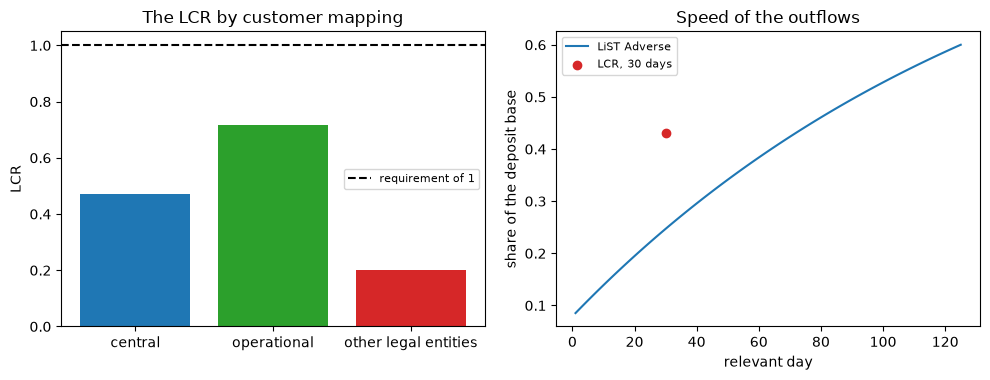

In [9]:
# Draw the LCR under the three mappings and the deposit outflow share of LiST Adverse against the LCR share
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))

labels = [names[entry["mapping_id"]] for entry in lcr["mapping_sensitivity"]]
left.bar(labels, band, color=["tab:blue", "tab:green", "tab:red"])
left.axhline(1.0, color="black", linestyle="--", label="requirement of 1")
left.set_ylabel("LCR")
left.set_title("The LCR by customer mapping")
left.legend(fontsize=8)

right.plot(np.arange(1, len(cumulative) + 1), cumulative, color="tab:blue", label="LiST Adverse")
right.scatter([30], [lcr_deposit_outflows / deposit_base], color="tab:red", zorder=3, label="LCR, 30 days")
right.set_xlabel("relevant day")
right.set_ylabel("share of the deposit base")
right.set_title("Speed of the outflows")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **HQLA.** The levels are 18.909 billion USD of Level 1, 31.204 of Level 2A and none of Level 2B. The adjustments are 0 for the 15% cap and 18.598 billion for the 40% cap, so the stock is 31.516 billion, by hand and by the engine, and Level 2 is exactly 0.4 of it. The document agrees.
- **Outflows, inflows and the ratio.** The outflows are 77.292 billion (60.637 from the uninsured balance at 40%, 13.899 from the foreign offices at 100%, 1.757 of secured funding and 0.999 from the insured deposits at 10%) and the inflows 10.612 billion, all counted because the 75% cap does not bind. The net outflow is 66.680 billion and the LCR is 31.516 / 66.680 = 0.472641, equal to the document.
- **The mapping.** The ratio is 0.4726 under the central mapping, 0.7172 if the uninsured balance is operational deposits and 0.1999 if it is other legal entities: a factor of more than three, with all three values reproduced. A single LCR for this bank would hide the band.
- **The NSFR.** With the stated bounds, the ASF is between 100.243 and 122.192 billion and the RSF between 47.670 and 167.277 billion, so the NSFR lies between 0.5993 and 2.5633. The band is too wide to say anything about compliance, and that is the lesson: the call-report aggregates do not identify the NSFR. This is a teaching computation on this notebook's mapping, not a result of the product.
- **LCR against survival.** The LCR assumes that 0.4304 of the deposit base leaves in 30 days (above the 3% to 40% range of the LCR deposit rates because the foreign-office balance is mapped at 100%); LiST Adverse has 0.247 after 30 days, reaches 0.4304 only on day 72 and 0.6001 on day 125. On the asset side the HQLA stock is 31.516 billion while the CBC is 71.673 billion. The LCR of 0.4726 and the survival period of 62 days are both right, for different assumptions on speed and on what is liquid.

What this notebook does not show: the LCR as a regulatory figure (the label of the document forbids it), the combined LCR and NSFR of a real filer, or the effect of a different horizon. The ratio is a property of the stated mapping and of synthetic behaviour.

## Summary

- HQLA is Level 1 plus Level 2A plus Level 2B less two cap adjustments; here the 40% Level 2 cap binds exactly.
- The net outflow is the outflow less the inflows up to 75% of it, and the ratio is the stock over it; the engine refuses an undefined ratio.
- The customer mapping of a call report is an assumption, and it moves the ratio by a factor of more than three; a result must show the band, not only the central value.
- The NSFR needs residual maturities that aggregates do not carry.
- The LCR and the survival period answer different questions with different assumptions on speed and on what is liquid; read them together.

**What to try next.** Move the uninsured balance to the category `operational_insured_portion` of the engine's table and see what the ratio does; then continue with notebook 06.

## References

- BCBS, Basel Framework, LCR standard (LCR20, LCR30, LCR40 and LCR99, in force 2019-12-15). https://www.bis.org/committees/bcbs/basel-framework/standard/lcr
- BCBS, Basel Framework, NSFR standard (NSF20, NSF30 and NSF99 Tables 1 to 3, in force 2019-12-15). https://www.bis.org/committees/bcbs/basel-framework/standard/nsf/99/inforce/2019-12-15/published/2019-12-15
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm